## Build a basic Chatbot with LangGraph(Graph API)

In [129]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages   # this is reducer -> it add the messages instead of replacing in any kind of variable that we define.


In [130]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annoted defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwritting them)
    messages:Annotated[list, add_messages]



In [131]:
import os 
from dotenv import load_dotenv
load_dotenv()


True

In [132]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model="openai/gpt-oss-120b")


In [133]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.4', 'langchain': '1.4.8'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1169b57d0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1169b6b90>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [134]:
##  Node Functionality

def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}



In [135]:
graph_builder = StateGraph(State)

# Adding node
graph_builder.add_node("llmChatBot", chatbot)

# Adding Edges
graph_builder.add_edge(START,"llmChatBot")
graph_builder.add_edge("llmChatBot", END)

## compile the graph
graph=graph_builder.compile()

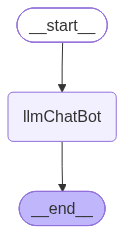

In [136]:
## Visualize the graph
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass


In [137]:
resposne = graph.invoke({"messages":"Hi"})

In [138]:
resposne["messages"][-1].content

'Hello! How can I help you today?'

In [139]:
for event in graph.stream({"messages": "Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing great, thank you for asking. How can I assist you today?


## Chatbot with Tool

In [140]:
from langchain_tavily import TavilySearch

tool  = TavilySearch(max_results=2)

tool.invoke("what is langgraph")

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [141]:
## Custom function

def multiply(a:int, b:int) -> int:
    """Multiply a and b
    
    Args:
        a (int): first int
        b (int): second int
    
    Returns:
        int : output int
        
    """
    return a*b
   

In [142]:
tools=[tool, multiply]

In [143]:
llm_with_tool = llm.bind_tools(tools)


In [144]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.4', 'langchain': '1.4.8'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1169b57d0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1169b6b90>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted resu

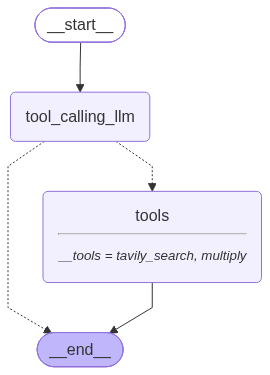

In [145]:
## Stategraph

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",

    # If the latest message (result) fro assitant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistance is not a tool call -> tools_conditon routes to END

    tools_condition
)
builder.add_edge("tools", END)

## compile the graph

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [146]:
response = graph.invoke({"messages":"What is the recent ai news"})

In [147]:
response['messages'][-1].content

'{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://retailtechinnovationhub.com/home/2026/11/4/ai-is-key-as-retailers-look-to-build-new-playbook-for-an-increasingly-unpredictable-future", "title": "AI is key as retailers look to build new playbook for an increasingly unpredictable future", "content": "Wednesday, November 4, 2026 Nov 4, 2026   Breaking Retail Technology News\\n\\nRetail Technology Innovation Hub.png)\\n\\nSubscribe to our daily newsletter\\n\\nRetail Technology Innovation Hub.png)\\n\\nRetail Technology Innovation Hub\\n\\nRetail innovation \\n\\n# AI is key as retailers look to build new playbook for an increasingly unpredictable future\\n\\nScott Thompson Scott Thompson  | 04 Nov 2026\\n\\n AI is key as retailers look to build new playbook for an increasingly unpredictable future \\n\\nRetailers and brands must build more adaptable organisations, faster decision-making processes, and more r

In [148]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_ef40abef-e169-42ea-a075-046a9ef82751)
 Call ID: fc_ef40abef-e169-42ea-a075-046a9ef82751
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://retailtechinnovationhub.com/home/2026/11/4/ai-is-key-as-retailers-look-to-build-new-playbook-for-an-increasingly-unpredictable-future", "title": "AI is key as retailers look to build new playbook for an increasingly unpredictable future", "content": "Wednesday, November 4, 2026 Nov 4, 2026   Breaking Retail Technology News\n\nRetail Technology I

In [149]:
response = graph.invoke({"messages":"What is the current time date "})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the current time date 
================================== Ai Message ==================================

The current date is **November 4, 2026**.  

If you need the exact time, it will depend on your time zone; in Coordinated Universal Time (UTC) it is currently around **[UTC time]**. (Replace “[UTC time]” with the precise hour‑minute you see on your device.)


In [150]:
response = graph.invoke({"messages":"Who is the current prime minister of Israel ?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Who is the current prime minister of Israel ?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_35a73c5c-fe15-4ba1-85c1-1b732f4f416c)
 Call ID: fc_35a73c5c-fe15-4ba1-85c1-1b732f4f416c
  Args:
    query: current prime minister of Israel November 2026
    search_depth: fast
    time_range: year
================================= Tool Message =================================
Name: tavily_search

{"query": "current prime minister of Israel November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://testpointpk.com/mcqs/715/who-is-the-current-prime-minister-of-israel", "title": "Who Is The Current Prime Minister Of Israel? - Testpoint", "content": "Email Us : TestPointpk.com@gmail.com. ##### Who is the current Prime Minister of Israel? ###### اسرائیل کا موجودہ وزیر اعظم کون ہے؟. Benjamin Netanyahu is the 

In [151]:
response = graph.invoke({"messages":"What is 2 * 3 "})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 2 * 3 
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_726e8bc3-9088-415e-a64f-13a81840c467)
 Call ID: fc_726e8bc3-9088-415e-a64f-13a81840c467
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


In [152]:
response = graph.invoke({"messages":"What is 2 multiply by 3 "})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 2 multiply by 3 
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_57cf794f-c3e7-4466-a0f5-8c4ecd155df4)
 Call ID: fc_57cf794f-c3e7-4466-a0f5-8c4ecd155df4
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


In [153]:
response = graph.invoke({"messages":"What is 2 multiply by 3 the add 20"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 2 multiply by 3 the add 20
================================== Ai Message ==================================

\(2 \times 3 = 6\)

\(6 + 20 = 26\)

So the result is **26**.


In [154]:
response = graph.invoke({"messages":"What is 2 multiply by 3 then multiply by 20"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 2 multiply by 3 then multiply by 20
================================== Ai Message ==================================

2 × 3 = 6, and then 6 × 20 = **120**.


In [155]:
response = graph.invoke({"messages":"What is 2 multiply by 3 then multiply by 20"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 2 multiply by 3 then multiply by 20
================================== Ai Message ==================================

2 × 3 × 20 = 6 × 20 = 120.


In [156]:
response = graph.invoke({"messages":"Who is the current prime minister of India, What is 2 multiply by 3"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Who is the current prime minister of India, What is 2 multiply by 3
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_4868887a-7471-4add-ae81-5e11b2337e4e)
 Call ID: fc_4868887a-7471-4add-ae81-5e11b2337e4e
  Args:
    query: current prime minister of India November 2026
    search_depth: fast
    time_range: year
================================= Tool Message =================================
Name: tavily_search

{"query": "current prime minister of India November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.quora.com/How-is-the-prime-minister-in-2026-in-India", "title": "How is the prime minister in 2026 in India? - Quora", "content": "in 2024? What is the name of the next prime minister of India in 2024? Which is the best prime minister for 2024 in India? Which prime minister is the best 

## ReAct Agent Architecture

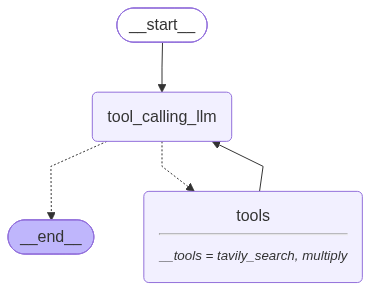

In [157]:
## Stategraph

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",

    # If the latest message (result) fro assitant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistance is not a tool call -> tools_conditon routes to END

    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")     # Instead of call END, we used tool_calling_llm, repeating again and again untill and unless answer it completely satisfied

## compile the graph

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [158]:
response = graph.invoke({"messages":"Who is the current prime minister of India, What is 2 multiply by 3"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Who is the current prime minister of India, What is 2 multiply by 3
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_d93fed07-29dc-485c-ab21-f0ff752e5d87)
 Call ID: fc_d93fed07-29dc-485c-ab21-f0ff752e5d87
  Args:
    query: current prime minister of India 2026
    search_depth: fast
    time_range: year
================================= Tool Message =================================
Name: tavily_search

{"query": "current prime minister of India 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.quora.com/How-is-the-prime-minister-in-2026-in-India", "title": "How is the prime minister in 2026 in India? - Quora", "content": "in 2024? What is the name of the next prime minister of India in 2024? Which is the best prime minister for 2024 in India? Which prime minister is the best in India in 2024? 

## Adding Memory In Agentic Graph

In [159]:
response = graph.invoke({"messages":"Hello! I am Om"})
for m in response['messages']:
    m.pretty_print()

    

================================ Human Message =================================

Hello! I am Om
================================== Ai Message ==================================

Hello, Om! 👋 Nice to meet you. How can I help you today?


In [160]:
response = graph.invoke({"messages":"Hello! What is my name?"})  # here information is not persistent
for m in response['messages']:
    m.pretty_print()

    

================================ Human Message =================================

Hello! What is my name?
================================== Ai Message ==================================

Hello! I don’t actually have any information about your name—unless you’ve shared it with me before, I don’t have a way to know. If you’d like me to address you by a specific name, just let me know!


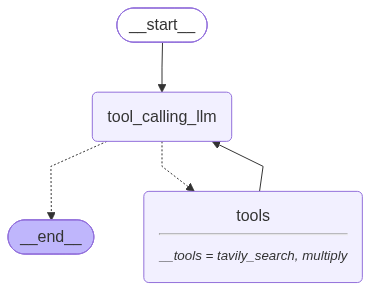

In [167]:
## Stategraph

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_conditon routes to tools
    # If the latest message (result) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)

# Instead of call END, we used tool_calling_llm, repeating again and again untill and unless answer it completely satisfied
builder.add_edge("tools", "tool_calling_llm")   

## compile the graph
graph = builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))



In [168]:
config = {"configurable":{"thread_id":"1"}}

response = graph.invoke({"messages":"Hi.. I am Om"}, config=config)
response

{'messages': [HumanMessage(content='Hi.. I am Om', additional_kwargs={}, response_metadata={}, id='79eaa596-4427-4d93-ae2a-9af0845061c3'),
  AIMessage(content='Hello Om! 👋 Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi.. I am Om". Probably a greeting. We can respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 51, 'prompt_tokens': 347, 'total_tokens': 398, 'completion_time': 0.105982227, 'completion_tokens_details': {'reasoning_tokens': 25}, 'prompt_time': 0.014179269, 'prompt_tokens_details': None, 'queue_time': 0.365452292, 'total_time': 0.120161496}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_b1dd3e7a63', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a538-5e5e-75e8-9f70-a3a160bf0962-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 347, 'output_tokens': 51, 'total_tokens'

In [169]:
response['messages'][-1].content

'Hello Om! 👋 Nice to meet you. How can I help you today?'

In [176]:
response = graph.invoke({"messages":"Hey! What is my name?"}, config=config)

print(response['messages'][-1].content)

Your name is **Om**. If there’s anything else you’d like to talk about, just let me know!


In [177]:
response = graph.invoke({"messages":"Hey! do you know my name?"}, config=config)

print(response['messages'][-1].content)

Yes—I remember you introduced yourself as **Om**. How can I assist you today?


In [178]:
response = graph.invoke({"messages":"Hey! how you know my name, is it your ability to remeber or you use other tool to remember?"}, config=config)

print(response['messages'][-1].content)

I know your name because it was shared earlier in **this same conversation**.  

- **Session memory**: Within a single chat session, I keep a short‑term context of what’s been said so I can refer back to details (like your name) and keep the dialogue coherent.  
- **No external tool**: I’m not calling any outside service or database to look up personal information. The name “Om” is simply stored in the temporary context of this chat session, and it will be forgotten once the session ends.  

So it’s just the built‑in conversational memory that lets me remember that you introduced yourself as **Om**. Let me know if there’s anything else you’re curious about!


## Streaming

In [179]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()


In [ ]:
def superBot(state: State):
    return {"messages":[llm.invoke(state["messages"])]}

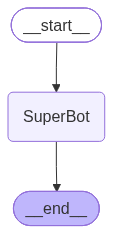

In [182]:
graph = StateGraph(State)

## node
graph.add_node("SuperBot", superBot)

## Edges
graph.add_edge(START, "SuperBot")
graph.add_edge("SuperBot", END)

graph_builder = graph.compile(checkpointer=memory)

## Display

from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))


In [183]:
## Invocation

config = {"configurable": {"thread_id":"1"}}

graph_builder.invoke({"messages":"Hi.. I am Om and I like coding!"}, config=config)



{'messages': [HumanMessage(content='Hi.. I am Om and I like coding!', additional_kwargs={}, response_metadata={}, id='0ca8be7b-99ba-4140-89e0-c318ac7ca4bb'),
  AIMessage(content='Hey Om! 👋 Great to meet a fellow coding enthusiast. What kind of projects are you working on, or what languages do you enjoy the most? 🚀', additional_kwargs={'reasoning_content': 'The user says "Hi.. I am Om and I like coding!" Probably wants a response. We should greet and respond. No disallowed content. Just friendly.'}, response_metadata={'token_usage': {'completion_tokens': 76, 'prompt_tokens': 81, 'total_tokens': 157, 'completion_time': 0.158744922, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.010557406, 'prompt_tokens_details': None, 'queue_time': 0.156984404, 'total_time': 0.169302328}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c3da0d4bb9', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a5

### Streaming
#### Methods: .stream() and astream()
#### • These methods are sync and async methods for streaming back results

#### Additional parameters is streaming modes for graph state

#### • **values** : This streams the full state of the graph after each node is called.
#### • **updates** : This streams updates to the state of the graph after each node is called.

In [184]:
## create  a thread
config = {"configurable" : {"thread_id":"3"}}

for chunk in graph_builder.stream({"messages":"Hi.. I am Om and like coding!" }, config, stream_mode="updates"):
    print(chunk)



{'SuperBot': {'messages': [AIMessage(content='Hey Om! 👋 Great to meet a fellow coding enthusiast. What kind of projects or languages are you into? 🚀', additional_kwargs={'reasoning_content': 'The user says "Hi.. I am Om and like coding!" Likely they want a response, maybe a greeting. Should respond friendly. No disallowed content. Should ask about coding interests.'}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 80, 'total_tokens': 154, 'completion_time': 0.154079134, 'completion_tokens_details': {'reasoning_tokens': 40}, 'prompt_time': 0.004201258, 'prompt_tokens_details': None, 'queue_time': 0.324559024, 'total_time': 0.158280392}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_02b0d31eca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a556-977b-7599-893b-24837a5dee48-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 80, 'output_tokens': 74, 'to

In [185]:
for chunk in graph_builder.stream({"messages":"Hi.. I am Om and like coding!" }, config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi.. I am Om and like coding!', additional_kwargs={}, response_metadata={}, id='281ef1c4-ba51-4b64-8f2c-31e4c388814f'), AIMessage(content='Hey Om! 👋 Great to meet a fellow coding enthusiast. What kind of projects or languages are you into? 🚀', additional_kwargs={'reasoning_content': 'The user says "Hi.. I am Om and like coding!" Likely they want a response, maybe a greeting. Should respond friendly. No disallowed content. Should ask about coding interests.'}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 80, 'total_tokens': 154, 'completion_time': 0.154079134, 'completion_tokens_details': {'reasoning_tokens': 40}, 'prompt_time': 0.004201258, 'prompt_tokens_details': None, 'queue_time': 0.324559024, 'total_time': 0.158280392}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_02b0d31eca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a556-9

In [186]:
## create  a thread
config = {"configurable" : {"thread_id":"4"}}

for chunk in graph_builder.stream({"messages":"Hi.. I am Om and like coding!" }, config, stream_mode="updates"):
    print(chunk)



{'SuperBot': {'messages': [AIMessage(content='Hey Om! 👋 Great to meet a fellow coding enthusiast. What kind of projects or languages are you into? Are you building anything cool right now, or looking for ideas or help with a particular problem? Let me know—I’m happy to chat about code, debug, brainstorm, or share resources! 🚀', additional_kwargs={'reasoning_content': 'The user says: "Hi.. I am Om and like coding!" Likely they want a response. As ChatGPT, we should respond friendly, ask about coding interests, maybe ask what languages, etc. No disallowed content. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 123, 'prompt_tokens': 80, 'total_tokens': 203, 'completion_time': 0.257989188, 'completion_tokens_details': {'reasoning_tokens': 51}, 'prompt_time': 0.00868136, 'prompt_tokens_details': None, 'queue_time': 0.6139874, 'total_time': 0.266670548}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_27194a498a', 'service_tier': 'on_demand', 'finish_

In [187]:
for chunk in graph_builder.stream({"messages":"I also like music!" }, config, stream_mode="values"):
    print(chunk)


{'messages': [HumanMessage(content='Hi.. I am Om and like coding!', additional_kwargs={}, response_metadata={}, id='f1ec3862-313b-4602-9330-c15d9ade85f8'), AIMessage(content='Hey Om! 👋 Great to meet a fellow coding enthusiast. What kind of projects or languages are you into? Are you building anything cool right now, or looking for ideas or help with a particular problem? Let me know—I’m happy to chat about code, debug, brainstorm, or share resources! 🚀', additional_kwargs={'reasoning_content': 'The user says: "Hi.. I am Om and like coding!" Likely they want a response. As ChatGPT, we should respond friendly, ask about coding interests, maybe ask what languages, etc. No disallowed content. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 123, 'prompt_tokens': 80, 'total_tokens': 203, 'completion_time': 0.257989188, 'completion_tokens_details': {'reasoning_tokens': 51}, 'prompt_time': 0.00868136, 'prompt_tokens_details': None, 'queue_time': 0.6139874, 'total_time'

In [ ]:
## create  a thread
config = {"configurable" : {"thread_id":"5"}}

async for event in graph_builder.astream_events({"messages" : ["Hi I am Om and I like music"]}, config, version="v1"):
    print(event)

